In [34]:
import pandas as pd
import numpy as np
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns

In [35]:
!pip install ucimlrepo

In [36]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
heart_disease = fetch_ucirepo(id=45)

# data (as pandas dataframes)
x = heart_disease.data.features
y = heart_disease.data.targets

In [37]:
# metadata
print(heart_disease.metadata)

{'uci_id': 45, 'name': 'Heart Disease', 'repository_url': 'https://archive.ics.uci.edu/dataset/45/heart+disease', 'data_url': 'https://archive.ics.uci.edu/static/public/45/data.csv', 'abstract': '4 databases: Cleveland, Hungary, Switzerland, and the VA Long Beach', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 303, 'num_features': 13, 'feature_types': ['Categorical', 'Integer', 'Real'], 'demographics': ['Age', 'Sex'], 'target_col': ['num'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1989, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C52P4X', 'creators': ['Andras Janosi', 'William Steinbrunn', 'Matthias Pfisterer', 'Robert Detrano'], 'intro_paper': {'ID': 231, 'type': 'NATIVE', 'title': 'International application of a new probability algorithm for the diagnosis of coronary artery disease.', 'authors': 'R. Detrano, A. Jánosi, W. Steinbrunn, M

In [38]:
# variable information
print(heart_disease.variables)

        name     role         type demographic  \
0        age  Feature      Integer         Age   
1        sex  Feature  Categorical         Sex   
2         cp  Feature  Categorical        None   
3   trestbps  Feature      Integer        None   
4       chol  Feature      Integer        None   
5        fbs  Feature  Categorical        None   
6    restecg  Feature  Categorical        None   
7    thalach  Feature      Integer        None   
8      exang  Feature  Categorical        None   
9    oldpeak  Feature      Integer        None   
10     slope  Feature  Categorical        None   
11        ca  Feature      Integer        None   
12      thal  Feature  Categorical        None   
13       num   Target      Integer        None   

                                          description  units missing_values  
0                                                None  years             no  
1                                                None   None             no  
2              

In [39]:
heart_disease_df = pd.DataFrame(heart_disease.data.features)
heart_disease_df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0


In [40]:
heart_disease_df["target"] = heart_disease.data.targets
heart_disease_df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [41]:
heart_disease_df["target"] = (heart_disease_df["target"] > 0).astype(int)


for column in heart_disease_df.columns:
    heart_disease_df[column] = pd.to_numeric(
        heart_disease_df[column],
        errors="coerce"
    )

In [42]:
heart_disease_df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [43]:
import os
os.makedirs("/content/Datasets", exist_ok=True)
heart_disease_df.to_csv(
    "/content/Datasets/heart_disease.csv",
    index=False
)

In [44]:
#Datasets shape
print(f"Heart disease : {heart_disease_df.shape}")

Heart disease : (303, 14)


In [45]:
#Datasets columns
print(f"Heart disease : {heart_disease_df.columns.tolist()}")

Heart disease : ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


In [46]:
#Datasets info
heart_disease_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


In [47]:
#Check null valuse
print(f"Heart disease :\n{heart_disease_df.isnull().sum()}\n")

print(f"Total nulls of heart disease : {heart_disease_df.isnull().sum().sum()}")

Heart disease :
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Total nulls of heart disease : 6


In [48]:
#Counting the target values
print(f"Heart disease :\n{heart_disease_df["target"].value_counts()}\n")

#Counting target values normally
print(f"Heart disease :\n{heart_disease_df["target"].value_counts(normalize=True)}")

Heart disease :
target
0    164
1    139
Name: count, dtype: int64

Heart disease :
target
0    0.541254
1    0.458746
Name: proportion, dtype: float64


In [49]:
#Describe datasets
heart_disease_df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.458746
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,0.499120
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,1.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,1.000000


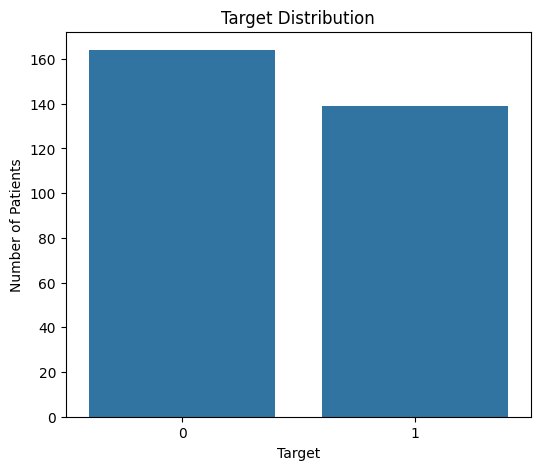

In [50]:
plt.figure(figsize=(6, 5))

sns.countplot(
    data=heart_disease_df,
    x="target"
)

plt.title("Target Distribution")
plt.xlabel("Target")
plt.ylabel("Number of Patients")

plt.show()

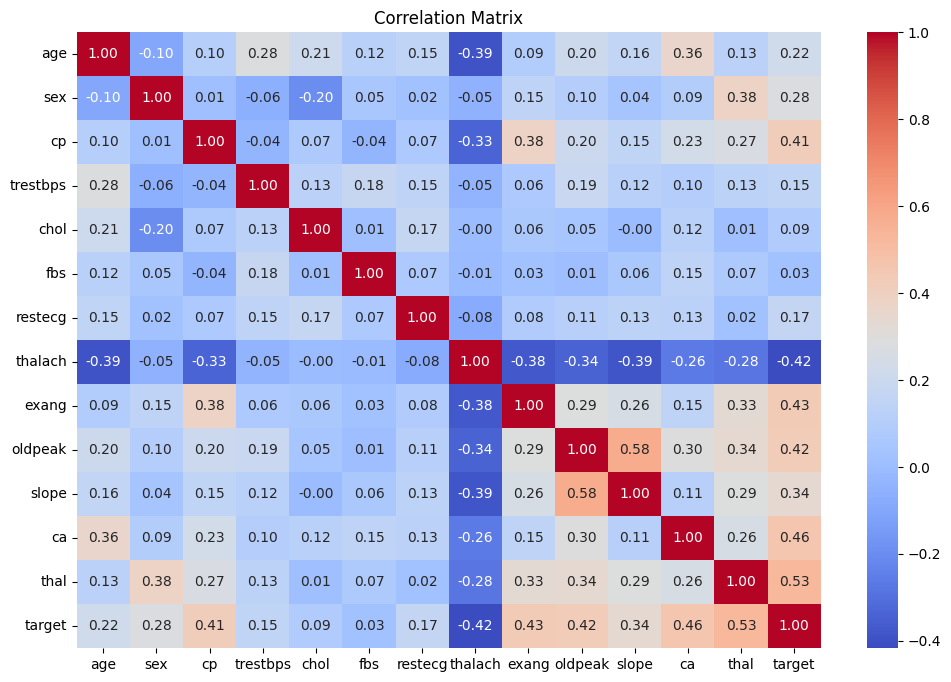

In [51]:
plt.figure(
    figsize=(12, 8)
)

correlation = heart_disease_df.corr(
    numeric_only=True
)

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title(
    "Correlation Matrix"
)

plt.show()

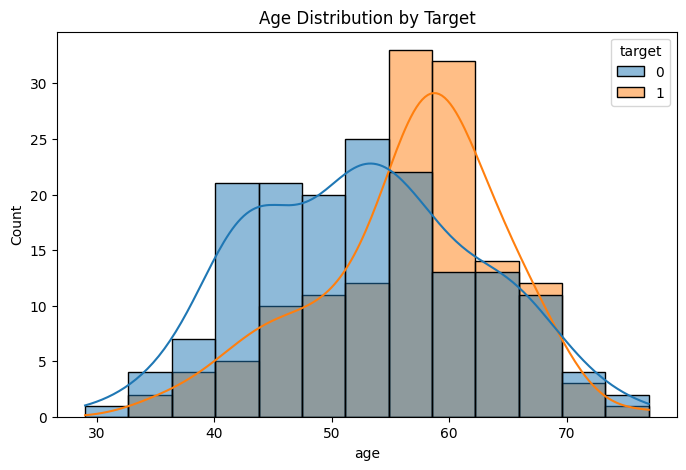

In [52]:
plt.figure(
    figsize=(8, 5)
)

sns.histplot(
    data=heart_disease_df,
    x="age",
    hue="target",
    kde=True
)

plt.title(
    "Age Distribution by Target"
)

plt.show()

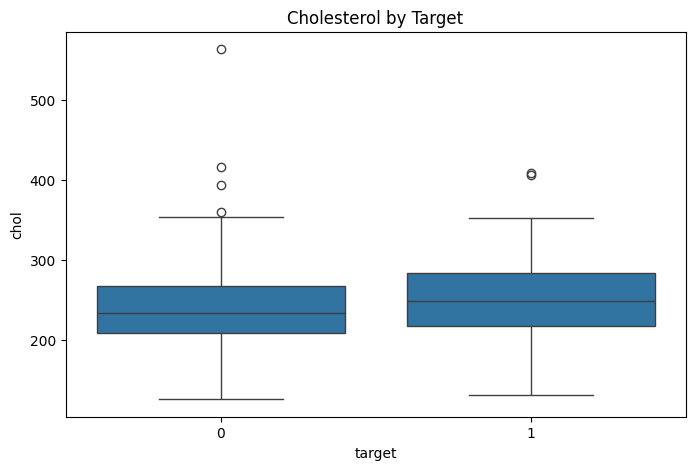

In [53]:
plt.figure(
    figsize=(8, 5)
)

sns.boxplot(
    data=heart_disease_df,
    x="target",
    y="chol"
)

plt.title(
    "Cholesterol by Target"
)

plt.show()

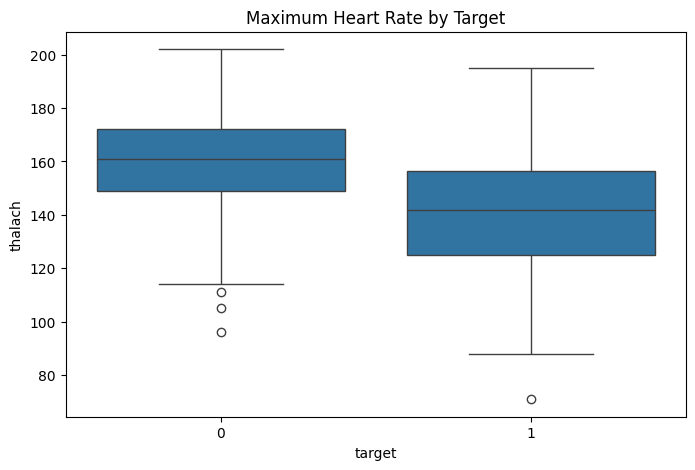

In [54]:
plt.figure(
    figsize=(8, 5)
)

sns.boxplot(
    data=heart_disease_df,
    x="target",
    y="thalach"
)

plt.title(
    "Maximum Heart Rate by Target"
)

plt.show()

In [55]:
# بررسی مجدد missing values
print(heart_disease_df.isnull().sum())

# روش پیشنهادی: پر کردن با median (چون ca و thal مقادیر گسسته دارن، می‌تونی از mode هم استفاده کنی)
heart_disease_df["ca"] = heart_disease_df["ca"].fillna(heart_disease_df["ca"].median())
heart_disease_df["thal"] = heart_disease_df["thal"].fillna(heart_disease_df["thal"].median())

# بررسی نهایی
print(f"\nTotal nulls after imputation: {heart_disease_df.isnull().sum().sum()}")

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Total nulls after imputation: 0


In [56]:
from sklearn.model_selection import train_test_split

# جدا کردن ویژگی‌ها و هدف
X = heart_disease_df.drop("target", axis=1)
y = heart_disease_df["target"]

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"\nTarget distribution:\n{y.value_counts()}")

X shape: (303, 13)
y shape: (303,)

Target distribution:
target
0    164
1    139
Name: count, dtype: int64


In [57]:
# تقسیم با stratified split برای حفظ توزیع کلاس‌ها
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,          # 20% برای تست
    random_state=42,         # برای تکرارپذیری
    stratify=y               # حفظ نسبت کلاس‌ها در هر دو مجموعه
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape:  {y_test.shape}")
print(f"\nTrain target distribution:\n{y_train.value_counts(normalize=True)}")
print(f"\nTest target distribution:\n{y_test.value_counts(normalize=True)}")

X_train shape: (242, 13)
X_test shape:  (61, 13)
y_train shape: (242,)
y_test shape:  (61,)

Train target distribution:
target
0    0.541322
1    0.458678
Name: proportion, dtype: float64

Test target distribution:
target
0    0.540984
1    0.459016
Name: proportion, dtype: float64


In [58]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# فقط روی train fit کن، روی test transform (جلوگیری از data leakage)
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling done!")
print(f"X_train_scaled mean: {X_train_scaled.mean():.4f}")
print(f"X_train_scaled std:  {X_train_scaled.std():.4f}")

Scaling done!
X_train_scaled mean: -0.0000
X_train_scaled std:  1.0000


In [59]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, classification_report
)
import pandas as pd
import numpy as np

# دیکشنری مدل‌ها
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Support Vector Machine": SVC(kernel="rbf", probability=True, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Naive Bayes": GaussianNB(),
}

# آموزش و ارزیابی هر مدل
results = []

for name, model in models.items():
    # آموزش
    model.fit(X_train_scaled, y_train)

    # پیش‌بینی
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]

    # محاسبه معیارها
    results.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall":    recall_score(y_test, y_pred),
        "F1-Score":  f1_score(y_test, y_pred),
        "ROC-AUC":   roc_auc_score(y_test, y_proba),
    })

# نمایش نتایج
results_df = pd.DataFrame(results).sort_values("F1-Score", ascending=False)
print(results_df.to_string(index=False))

                 Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC
   K-Nearest Neighbors  0.885246   0.800000 1.000000  0.888889 0.923160
         Random Forest  0.885246   0.818182 0.964286  0.885246 0.951299
           Naive Bayes  0.868852   0.794118 0.964286  0.870968 0.952381
   Logistic Regression  0.868852   0.812500 0.928571  0.866667 0.951299
     Gradient Boosting  0.852459   0.787879 0.928571  0.852459 0.945887
Support Vector Machine  0.852459   0.806452 0.892857  0.847458 0.943723
         Decision Tree  0.721311   0.657143 0.821429  0.730159 0.728896


/tmp/ipykernel_6040/3021617196.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


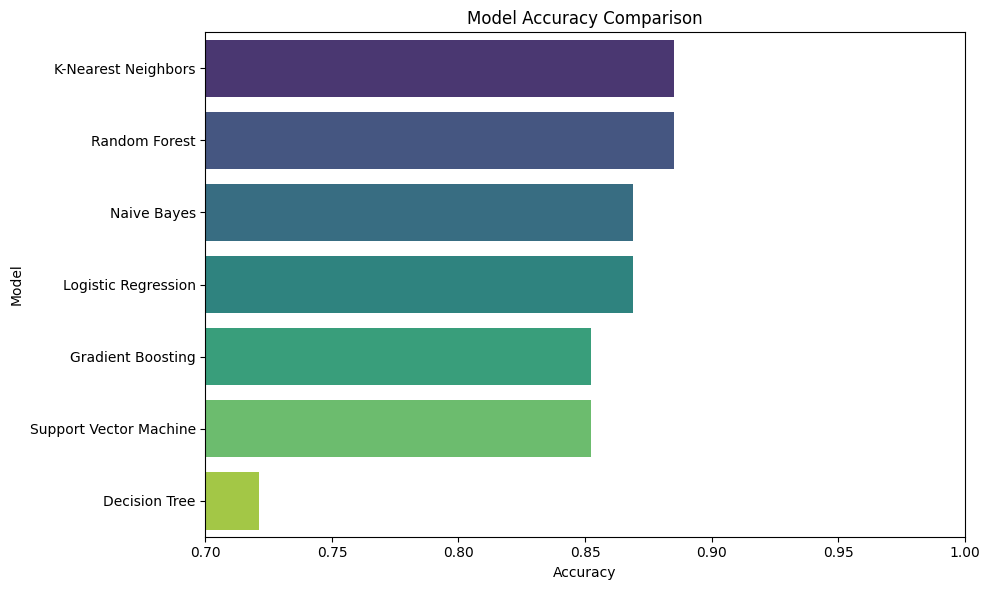

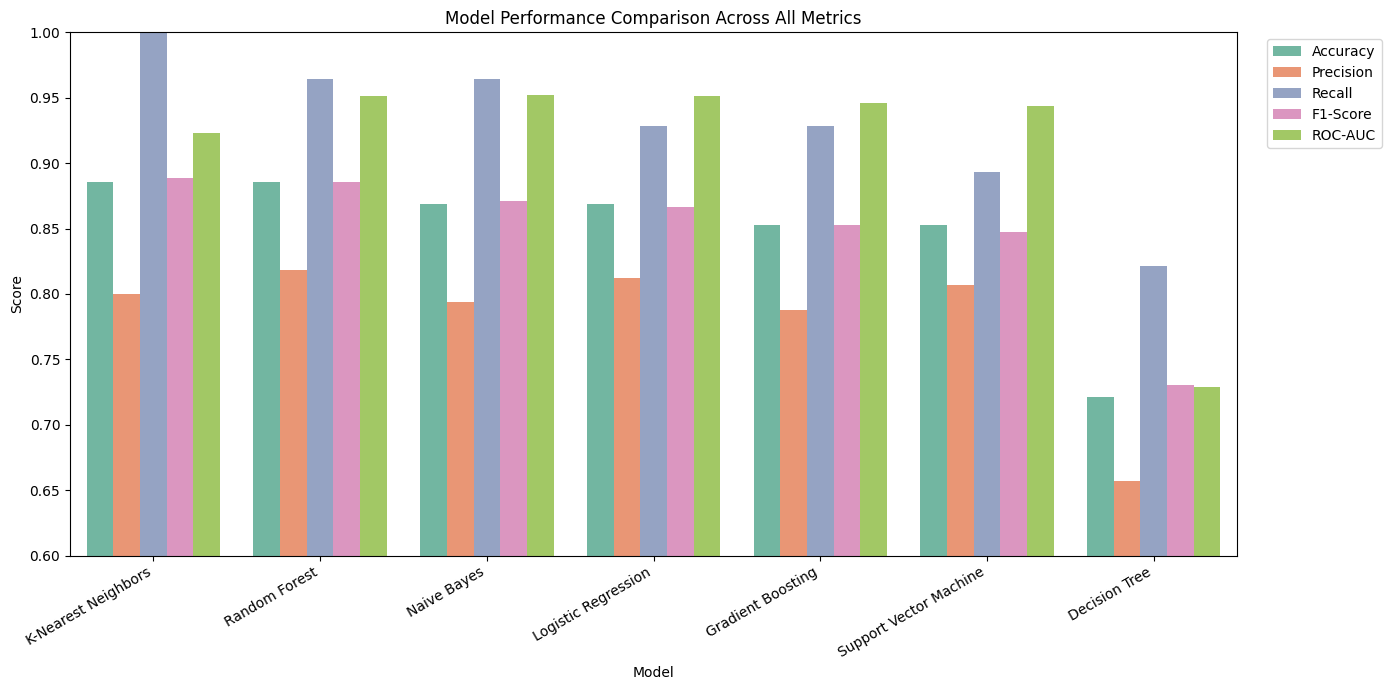

In [60]:
import matplotlib.pyplot as plt
import seaborn as sns

# نمودار مقایسه Accuracy
plt.figure(figsize=(10, 6))
sns.barplot(
    data=results_df,
    x="Accuracy",
    y="Model",
    palette="viridis"
)
plt.title("Model Accuracy Comparison")
plt.xlabel("Accuracy")
plt.xlim(0.7, 1.0)
plt.tight_layout()
plt.show()

# نمودار مقایسه همه معیارها
metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
results_melted = results_df.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(14, 7))
sns.barplot(
    data=results_melted,
    x="Model",
    y="Score",
    hue="Metric",
    palette="Set2"
)
plt.title("Model Performance Comparison Across All Metrics")
plt.xticks(rotation=30, ha="right")
plt.ylim(0.6, 1.0)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

🏆 Best Model: K-Nearest Neighbors

Classification Report:
              precision    recall  f1-score   support

  No Disease       1.00      0.79      0.88        33
     Disease       0.80      1.00      0.89        28

    accuracy                           0.89        61
   macro avg       0.90      0.89      0.89        61
weighted avg       0.91      0.89      0.88        61



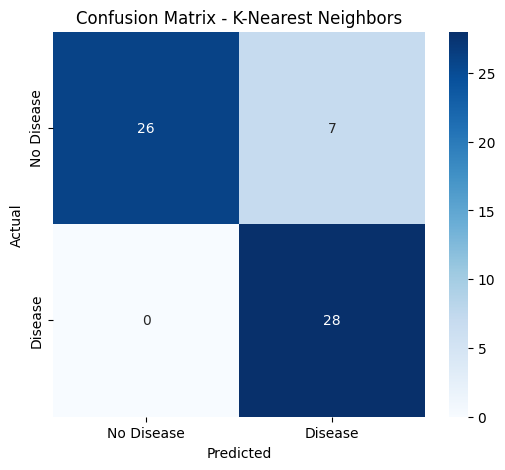

In [61]:
# انتخاب بهترین مدل بر اساس F1-Score (چون هم Precision و هم Recall مهمه)
best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]

print(f"🏆 Best Model: {best_model_name}\n")

# پیش‌بینی مجدد
y_pred_best = best_model.predict(X_test_scaled)
y_proba_best = best_model.predict_proba(X_test_scaled)[:, 1]

# Classification Report
print("Classification Report:")
print(classification_report(y_test, y_pred_best, target_names=["No Disease", "Disease"]))

# Confusion Matrix
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_best)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)
plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [62]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []
for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train_scaled, y_train,
        cv=cv,
        scoring="f1"     # می‌تونی "accuracy" یا "roc_auc" هم بذاری
    )
    cv_results.append({
        "Model": name,
        "CV Mean F1": scores.mean(),
        "CV Std F1":  scores.std()
    })

cv_df = pd.DataFrame(cv_results).sort_values("CV Mean F1", ascending=False)
print(cv_df.to_string(index=False))

                 Model  CV Mean F1  CV Std F1
   Logistic Regression    0.800737   0.026041
   K-Nearest Neighbors    0.799422   0.033306
           Naive Bayes    0.795217   0.037461
Support Vector Machine    0.792987   0.044477
         Random Forest    0.770585   0.031800
     Gradient Boosting    0.759815   0.054301
         Decision Tree    0.674417   0.026975


In [63]:
from sklearn.model_selection import GridSearchCV

# مثال برای Random Forest (اگه برنده شد)
param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 5, 10, 15],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_scaled, y_train)

print(f"Best Params: {grid_search.best_params_}")
print(f"Best CV Score: {grid_search.best_score_:.4f}")

# ارزیابی روی test
best_tuned_model = grid_search.best_estimator_
y_pred_tuned = best_tuned_model.predict(X_test_scaled)
print(f"\nTest F1-Score: {f1_score(y_test, y_pred_tuned):.4f}")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred_tuned):.4f}")

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best Params: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}
Best CV Score: 0.8106

Test F1-Score: 0.8966
Test Accuracy: 0.9016


In [64]:
import joblib

# ذخیره مدل و scaler
joblib.dump(best_tuned_model, "/content/Datasets/best_heart_disease_model.pkl")
joblib.dump(scaler, "/content/Datasets/scaler.pkl")
print("✅ Tuned Random Forest model and scaler saved successfully!")

✅ Tuned Random Forest model and scaler saved successfully!


In [65]:
# اضافه کن به نتایج، مدل tuned رو:
y_pred_tuned = best_tuned_model.predict(X_test_scaled)
y_proba_tuned = best_tuned_model.predict_proba(X_test_scaled)[:, 1]

results_df.loc[len(results_df)] = {
    "Model": "Tuned Random Forest",
    "Accuracy": accuracy_score(y_test, y_pred_tuned),
    "Precision": precision_score(y_test, y_pred_tuned),
    "Recall": recall_score(y_test, y_pred_tuned),
    "F1-Score": f1_score(y_test, y_pred_tuned),
    "ROC-AUC": roc_auc_score(y_test, y_proba_tuned),
}

results_df = results_df.sort_values("F1-Score", ascending=False)
print(results_df.to_string(index=False))

                 Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC
   Tuned Random Forest  0.901639   0.866667 0.928571  0.896552 0.948052
   K-Nearest Neighbors  0.885246   0.800000 1.000000  0.888889 0.923160
         Random Forest  0.885246   0.818182 0.964286  0.885246 0.951299
           Naive Bayes  0.868852   0.794118 0.964286  0.870968 0.952381
   Logistic Regression  0.868852   0.812500 0.928571  0.866667 0.951299
     Gradient Boosting  0.852459   0.787879 0.928571  0.852459 0.945887
Support Vector Machine  0.852459   0.806452 0.892857  0.847458 0.943723
         Decision Tree  0.721311   0.657143 0.821429  0.730159 0.728896
